# EN3150 Assignment 03: Optimizer Selection & Tuning (Member 3)

This notebook is a **controlled experiment** that isolates the effect of the optimizer on training.
Everything except the optimizer is held fixed:

| Held constant | Value |
|---|---|
| Network | Model A (Member 1's standard CNN, 45,643 parameters) |
| Data | GTSRB, 64x64, identical 70/15/15 split (seed 42), same augmentation |
| Initial weights | One saved random initialisation, re-loaded for every run |
| Mini-batch order | Same shuffling seed for every run |
| Epochs / batch size / loss | 20 / 32 / cross-entropy |

**Runs**

1. **SGD** (η = 0.01, no momentum)
2. **SGD + Momentum** (η = 0.01, β = 0.9)
3. **Adam** (η = 0.001, β₁ = 0.9, β₂ = 0.999) ← the optimizer the group selected
4. *Momentum sweep:* β ∈ {0.5, 0.99} at η = 0.01 (β = 0 and β = 0.9 reuse runs 1 and 2)
5. *Control:* SGD with η = 0.1, i.e. the same **effective** step size as momentum 0.9
   (η / (1 − β) = 0.01 / 0.1 = 0.1), to separate "momentum smooths the direction"
   from "momentum just takes bigger steps".

Outputs (saved to `outputs_member3/`): overlaid convergence plots, a per-iteration loss plot that
shows oscillation, a momentum-sweep plot, and a summary table (test accuracy, precision, recall).

## 0. Setup


In [1]:
import os, json, time, copy, random
import numpy as np
import torch

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0
OUT_DIR = "outputs_member3"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"Device: {device}")

Device: cuda


## 1. Data pipeline (identical split to Member 1)

In [7]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, random_split
try:
    from tqdm.auto import tqdm          # progress bar (optional)
except ImportError:                     # works without tqdm installed
    def tqdm(iterable, **kwargs):
        return iterable

# Same normalisation as Member 1 ([-1, 1]) because Model A is trained from scratch
NORM_MEAN, NORM_STD = (0.5,), (0.5,)
BATCH_SIZE = 32

# Same augmentations as Member 1 (no horizontal flips: they would change sign meaning)
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ColorJitter(brightness=0.2),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])
eval_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

raw_dataset = datasets.GTSRB(root="./data", split="train", download=True)


class CachedResizedDataset(Dataset):
    """Loads every GTSRB image ONCE, resizes it to 64x64 and keeps it in RAM.

    Member 1's pipeline resizes to 64x64 as its first transform, so resizing here
    gives exactly the same pixels; it just avoids re-reading ~26k files from disk
    every epoch (several training runs would otherwise be disk-bound).
    """
    def __init__(self, base):
        self.images, self.labels = [], []
        for img, label in tqdm(base, desc="Caching 64x64 images"):
            self.images.append(img.convert("RGB").resize((64, 64), resample=2))  # 2 = BILINEAR
            self.labels.append(int(label))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.images[i], self.labels[i]


cached_dataset = CachedResizedDataset(raw_dataset)

# 70/15/15 split with the SAME seed and sizes as Member 1 -> identical indices
total_size = len(cached_dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size
generator = torch.Generator().manual_seed(42)
train_subset, val_subset, test_subset = random_split(
    cached_dataset, [train_size, val_size, test_size], generator=generator
)


class SubsetWrapper(Dataset):
    """Applies a transform to a Subset (augmentation only on the training subset)."""
    def __init__(self, subset, transform=None):
        self.subset, self.transform = subset, transform

    def __getitem__(self, index):
        image, label = self.subset[index]
        if self.transform:
            image = self.transform(image)
        return image, label

    def __len__(self):
        return len(self.subset)


train_data = SubsetWrapper(train_subset, transform=train_transforms)
val_data = SubsetWrapper(val_subset, transform=eval_transforms)
test_data = SubsetWrapper(test_subset, transform=eval_transforms)

print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")
# Cross-check these against Member 1's notebook (train_subset.indices[:10]) to confirm the split matches
print("First 10 train indices:", train_subset.indices[:10])
print("First 10 test indices: ", test_subset.indices[:10])
assert (len(train_data), len(val_data), len(test_data)) == (18648, 3996, 3996)

Train: 18648, Val: 3996, Test: 3996
First 10 train indices: [7782, 12493, 1134, 3868, 16314, 8695, 25534, 25681, 7206, 14960]
First 10 test indices:  [16146, 20109, 13872, 6038, 12506, 11852, 5339, 3771, 3204, 11921]


## 2. Model A (copied unchanged from Member 1)

In [8]:
import torch.nn as nn

class ModelA(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(512, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


# One fixed random initialisation shared by every optimizer run (fair comparison)
set_seed()
INIT_STATE = copy.deepcopy(ModelA().state_dict())
n_params = sum(p.numel() for p in ModelA().parameters() if p.requires_grad)
print(f"Model A trainable parameters: {n_params:,}")
assert n_params == 45643

Model A trainable parameters: 45,643


## 3. Training / evaluation utilities

In [9]:
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 20
criterion = nn.CrossEntropyLoss()


def make_loaders():
    """Fresh loaders with a fixed shuffle seed -> every run sees batches in the same order."""
    g = torch.Generator().manual_seed(SEED)
    kw = dict(batch_size=32, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
    return (DataLoader(train_data, shuffle=True, generator=g, **kw),
            DataLoader(val_data, shuffle=False, **kw),
            DataLoader(test_data, shuffle=False, **kw))


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return total_loss / len(labels), accuracy_score(labels, preds), preds, labels


def run_experiment(name, make_optimizer):
    """Train Model A from the shared initialisation with the given optimizer."""
    set_seed()
    model = ModelA().to(device)
    model.load_state_dict(INIT_STATE)
    optimizer = make_optimizer(model.parameters())
    train_loader, val_loader, test_loader = make_loaders()

    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "epoch_time"]}
    hist["iter_loss"] = []  # every mini-batch loss -> shows oscillation / smoothing

    for epoch in range(EPOCHS):
        model.train()
        t0, run_loss, correct, seen = time.time(), 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            hist["iter_loss"].append(loss.item())
            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            seen += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()
        hist["epoch_time"].append(time.time() - t0)
        hist["train_loss"].append(run_loss / seen)
        hist["train_acc"].append(correct / seen)
        vl, va, _, _ = evaluate(model, val_loader)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"[{name}] epoch {epoch+1:02d}/{EPOCHS} | train loss {hist['train_loss'][-1]:.4f} "
              f"acc {hist['train_acc'][-1]:.4f} | val loss {vl:.4f} acc {va:.4f} | "
              f"{hist['epoch_time'][-1]:.1f}s")

    _, test_acc, preds, labels = evaluate(model, test_loader)
    hist["test"] = {
        "accuracy": test_acc,
        "precision_macro": precision_score(labels, preds, average="macro", zero_division=0),
        "recall_macro": recall_score(labels, preds, average="macro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    }
    print(f"[{name}] TEST: {hist['test']}\n")
    return hist

## 4. Run the experiments
Set `RUN_EXTRA = False` to run only the three required optimizers (≈ half the time).

In [10]:
RUN_EXTRA = True   # momentum sweep (beta = 0.5, 0.99) + matched-effective-step SGD control

EXPERIMENTS = {
    "SGD (lr=0.01)":               lambda p: optim.SGD(p, lr=0.01),
    "SGD+Momentum (lr=0.01, b=0.9)": lambda p: optim.SGD(p, lr=0.01, momentum=0.9),
    "Adam (lr=0.001)":             lambda p: optim.Adam(p, lr=0.001),
}
if RUN_EXTRA:
    EXPERIMENTS.update({
        "SGD+Momentum (lr=0.01, b=0.5)":  lambda p: optim.SGD(p, lr=0.01, momentum=0.5),
        "SGD+Momentum (lr=0.01, b=0.99)": lambda p: optim.SGD(p, lr=0.01, momentum=0.99),
        "SGD (lr=0.1)":                   lambda p: optim.SGD(p, lr=0.1),
    })

results = {}
for name, make_opt in EXPERIMENTS.items():
    results[name] = run_experiment(name, make_opt)
    with open(f"{OUT_DIR}/optimizer_results.json", "w") as f:   # save after every run
        json.dump(results, f)

[SGD (lr=0.01)] epoch 01/20 | train loss 3.5547 acc 0.0651 | val loss 3.4756 acc 0.0748 | 22.9s
[SGD (lr=0.01)] epoch 02/20 | train loss 3.3933 acc 0.0983 | val loss 3.2405 acc 0.1326 | 24.0s
[SGD (lr=0.01)] epoch 03/20 | train loss 2.8663 acc 0.2210 | val loss 2.3500 acc 0.3536 | 24.0s
[SGD (lr=0.01)] epoch 04/20 | train loss 1.8584 acc 0.4541 | val loss 1.4778 acc 0.5503 | 24.0s
[SGD (lr=0.01)] epoch 05/20 | train loss 1.2260 acc 0.6202 | val loss 0.9294 acc 0.7165 | 24.0s
[SGD (lr=0.01)] epoch 06/20 | train loss 0.8825 acc 0.7212 | val loss 0.7225 acc 0.7805 | 24.0s
[SGD (lr=0.01)] epoch 07/20 | train loss 0.6523 acc 0.7937 | val loss 0.5853 acc 0.8211 | 24.1s
[SGD (lr=0.01)] epoch 08/20 | train loss 0.4977 acc 0.8409 | val loss 0.4583 acc 0.8609 | 24.1s
[SGD (lr=0.01)] epoch 09/20 | train loss 0.4032 acc 0.8729 | val loss 0.3204 acc 0.9022 | 24.1s
[SGD (lr=0.01)] epoch 10/20 | train loss 0.3213 acc 0.8978 | val loss 0.3144 acc 0.8964 | 26.3s
[SGD (lr=0.01)] epoch 11/20 | train loss

## 5. Convergence plots

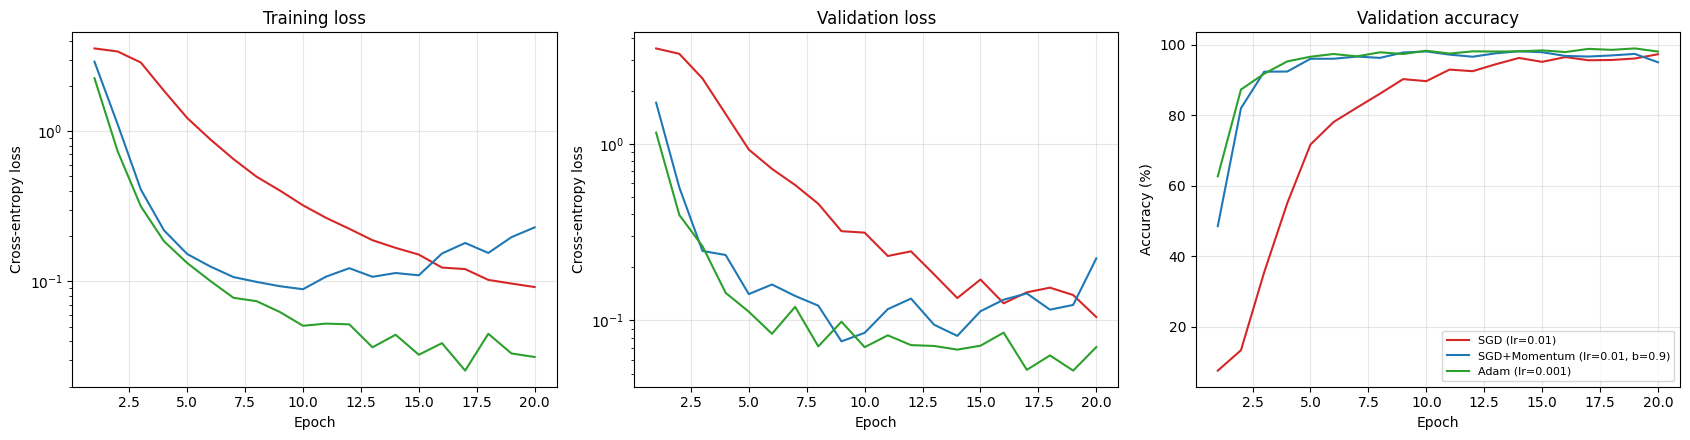

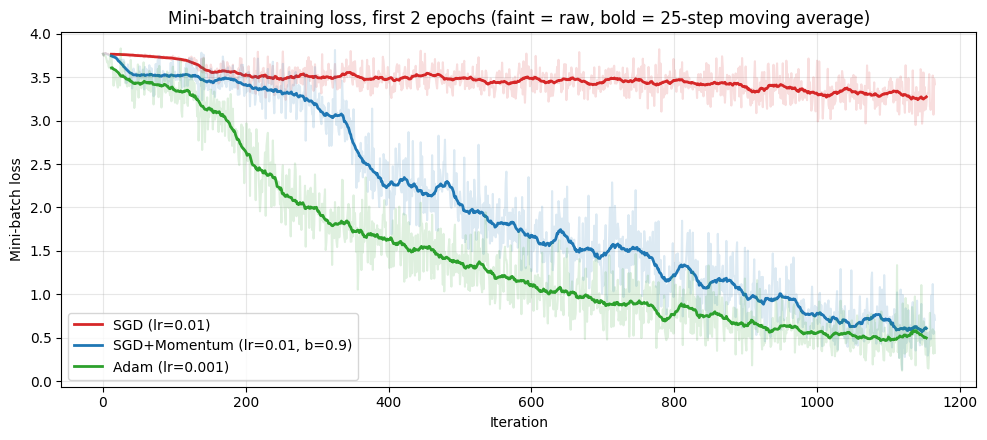

In [11]:
import matplotlib.pyplot as plt

MAIN = ["SGD (lr=0.01)", "SGD+Momentum (lr=0.01, b=0.9)", "Adam (lr=0.001)"]
COLORS = {MAIN[0]: "tab:red", MAIN[1]: "tab:blue", MAIN[2]: "tab:green"}
ep = np.arange(1, EPOCHS + 1)

# (a) Overlaid loss and accuracy curves for the three required optimizers
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for n in MAIN:
    h = results[n]
    axes[0].plot(ep, h["train_loss"], "-", color=COLORS[n], label=n)
    axes[1].plot(ep, h["val_loss"], "-", color=COLORS[n], label=n)
    axes[2].plot(ep, np.array(h["val_acc"]) * 100, "-", color=COLORS[n], label=n)
for ax, t, yl in zip(axes, ["Training loss", "Validation loss", "Validation accuracy"],
                     ["Cross-entropy loss", "Cross-entropy loss", "Accuracy (%)"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.set_ylabel(yl); ax.grid(alpha=0.3)
axes[0].set_yscale("log"); axes[1].set_yscale("log")
axes[2].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/optimizer_convergence.png", dpi=200); plt.show()

# (b) Per-iteration loss over the first 2 epochs: raw (faint) + moving average (bold)
def moving_avg(x, k=25):
    return np.convolve(x, np.ones(k) / k, mode="valid")

iters_per_epoch = len(results[MAIN[0]]["iter_loss"]) // EPOCHS
n_it = 2 * iters_per_epoch
plt.figure(figsize=(10, 4.5))
for n in MAIN:
    il = np.array(results[n]["iter_loss"][:n_it])
    plt.plot(il, color=COLORS[n], alpha=0.15)
    plt.plot(np.arange(len(moving_avg(il))) + 12, moving_avg(il), color=COLORS[n], lw=2, label=n)
plt.title("Mini-batch training loss, first 2 epochs (faint = raw, bold = 25-step moving average)")
plt.xlabel("Iteration"); plt.ylabel("Mini-batch loss"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/optimizer_iteration_loss.png", dpi=200); plt.show()

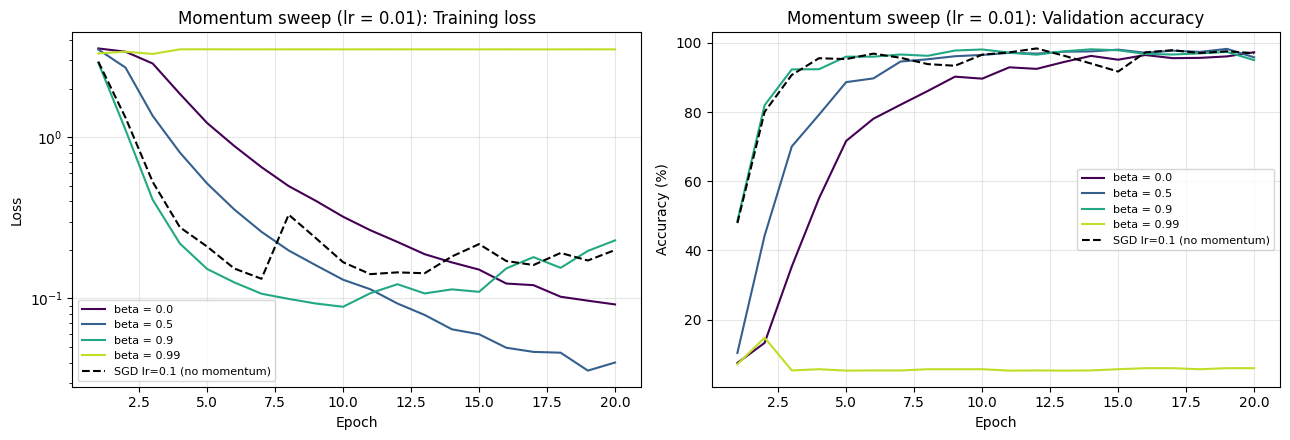

In [12]:
# (c) Momentum sweep: effect of beta at fixed lr = 0.01
SWEEP = [("SGD (lr=0.01)", 0.0), ("SGD+Momentum (lr=0.01, b=0.5)", 0.5),
         ("SGD+Momentum (lr=0.01, b=0.9)", 0.9), ("SGD+Momentum (lr=0.01, b=0.99)", 0.99)]
SWEEP = [(n, b) for n, b in SWEEP if n in results]
if len(SWEEP) > 2:
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(SWEEP)))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for (n, b), c in zip(SWEEP, cmap):
        axes[0].plot(ep, results[n]["train_loss"], color=c, label=f"beta = {b}")
        axes[1].plot(ep, np.array(results[n]["val_acc"]) * 100, color=c, label=f"beta = {b}")
    if "SGD (lr=0.1)" in results:  # matched effective step size control
        axes[0].plot(ep, results["SGD (lr=0.1)"]["train_loss"], "k--", label="SGD lr=0.1 (no momentum)")
        axes[1].plot(ep, np.array(results["SGD (lr=0.1)"]["val_acc"]) * 100, "k--",
                     label="SGD lr=0.1 (no momentum)")
    axes[0].set_yscale("log")
    for ax, t, yl in zip(axes, ["Training loss", "Validation accuracy"], ["Loss", "Accuracy (%)"]):
        ax.set_title(f"Momentum sweep (lr = 0.01): {t}"); ax.set_xlabel("Epoch")
        ax.set_ylabel(yl); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/momentum_sweep.png", dpi=200); plt.show()

## 6. Summary table (copy into Section 3 of the report)

In [13]:
import pandas as pd

def epochs_to(acc_list, target):
    hits = [i + 1 for i, a in enumerate(acc_list) if a >= target]
    return hits[0] if hits else None

rows = []
for n, h in results.items():
    rows.append({
        "Optimizer": n,
        "Epochs to 95% val acc": epochs_to(h["val_acc"], 0.95),
        "Final train loss": round(h["train_loss"][-1], 4),
        "Final val loss": round(h["val_loss"][-1], 4),
        "Best val acc (%)": round(100 * max(h["val_acc"]), 2),
        "Test acc (%)": round(100 * h["test"]["accuracy"], 2),
        "Test precision (macro, %)": round(100 * h["test"]["precision_macro"], 2),
        "Test recall (macro, %)": round(100 * h["test"]["recall_macro"], 2),
        "Mean epoch time (s)": round(float(np.mean(h["epoch_time"])), 1),
        # std of the last-epoch mini-batch losses: a simple "noise / oscillation" measure
        "Last-epoch batch-loss std": round(float(np.std(h["iter_loss"][-iters_per_epoch:])), 4),
    })
summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT_DIR}/optimizer_summary.csv", index=False)
display(summary)
print(summary.to_latex(index=False, float_format="%.2f"))

,Optimizer,Epochs to 95% val acc,Final train loss,Final val loss,Best val acc (%),Test acc (%),"Test precision (macro, %)","Test recall (macro, %)",Mean epoch time (s),Last-epoch batch-loss std
0,SGD (lr=0.01),14.0,0.0918,0.1045,97.27,97.10,97.41,97.66,24.1,0.0851
1,"SGD+Momentum (lr=0.01, b=0.9)",5.0,0.2292,0.2249,98.12,94.92,92.66,93.72,24.0,0.2437
2,Adam (lr=0.001),4.0,0.0314,0.0707,98.92,98.15,98.14,97.48,24.3,0.0559
3,"SGD+Momentum (lr=0.01, b=0.5)",8.0,0.0401,0.2219,98.25,95.62,96.17,96.48,24.4,0.0632
4,"SGD+Momentum (lr=0.01, b=0.99)",NaN,3.5083,3.4962,14.76,5.83,0.14,2.33,24.1,0.1236
5,SGD (lr=0.1),4.0,0.1997,0.1784,98.37,96.60,96.47,96.72,24.1,0.2481


\begin{tabular}{lrrrrrrrrr}
\toprule
Optimizer & Epochs to 95% val acc & Final train loss & Final val loss & Best val acc (%) & Test acc (%) & Test precision (macro, %) & Test recall (macro, %) & Mean epoch time (s) & Last-epoch batch-loss std \\
\midrule
SGD (lr=0.01) & 14.00 & 0.09 & 0.10 & 97.27 & 97.10 & 97.41 & 97.66 & 24.10 & 0.09 \\
SGD+Momentum (lr=0.01, b=0.9) & 5.00 & 0.23 & 0.22 & 98.12 & 94.92 & 92.66 & 93.72 & 24.00 & 0.24 \\
Adam (lr=0.001) & 4.00 & 0.03 & 0.07 & 98.92 & 98.15 & 98.14 & 97.48 & 24.30 & 0.06 \\
SGD+Momentum (lr=0.01, b=0.5) & 8.00 & 0.04 & 0.22 & 98.25 & 95.62 & 96.17 & 96.48 & 24.40 & 0.06 \\
SGD+Momentum (lr=0.01, b=0.99) & NaN & 3.51 & 3.50 & 14.76 & 5.83 & 0.14 & 2.33 & 24.10 & 0.12 \\
SGD (lr=0.1) & 4.00 & 0.20 & 0.18 & 98.37 & 96.60 & 96.47 & 96.72 & 24.10 & 0.25 \\
\bottomrule
\end{tabular}



## 7. Conclusions

**Selected optimizer: Adam with learning rate η = 0.001.**

- **Fastest convergence:** 95% validation accuracy after 4 epochs (SGD + Momentum 0.9: 5, plain SGD: 14).
- **Best and most stable result:** highest best validation accuracy (98.92%) and test accuracy (98.15%), the lowest
  final training loss (0.031) and the smoothest mini-batch loss in the last epoch (std 0.056, vs 0.085 for SGD and
  0.244 for SGD + Momentum 0.9).
- **No tuning needed:** Adam scales each parameter's step using running estimates of the mean and variance of its
  gradient, so the standard η = 0.001 works without a learning-rate search. The SGD variants depend strongly on the
  hand-picked η and β, as the runs below show.
- Every run is tested with its **final-epoch** weights, so test accuracy also reflects how stable training is at the end.

**Plain SGD (η = 0.01)** is stable but slow: the mini-batch loss barely moves from its starting value during the
first two epochs (ln 43 ≈ 3.76 is the loss of random guessing), validation accuracy is only 71.6% after 5 epochs, and
95% is reached at epoch 14. It ends close to Adam (97.10% test) because it never becomes unstable.

**Impact of the momentum parameter β (η = 0.01 in all runs):**

| β | Epochs to 95% val acc | Best val acc | Test acc | Behaviour |
|---|---|---|---|---|
| 0 (plain SGD) | 14 | 97.27% | 97.10% | slow, steady |
| 0.5 | 8 | 98.25% | 95.62% | faster |
| 0.9 | 5 | 98.12% | 94.92% | fastest early, unstable later |
| 0.99 | never | 14.76% | 5.83% | fails to train |

- Momentum keeps a decaying sum of past gradients (a velocity), so steps grow along directions that consistently
  reduce the loss. Larger β gives faster early convergence: 14 → 8 → 5 epochs to reach 95%.
- Too much momentum overshoots. With β = 0.9 the training loss is lowest at epoch 10 (0.089) and then rises to
  0.229 by epoch 20, and its mini-batch loss is the noisiest (std 0.244), so the final weights are worse than its best
  epoch (94.92% test vs 98.12% best validation). With β = 0.99 the velocity grows so large that training becomes
  unstable in the first epochs and never recovers: the training loss stays at about 3.5, close to random guessing.
- **Control run:** SGD with η = 0.1 has the same effective step size as momentum 0.9 (η / (1 − β) = 0.01 / 0.1 = 0.1)
  and behaves almost the same: 95% at epoch 4 (vs 5), similar late-training noise (std 0.248 vs 0.244) and the same
  rise in training loss later on. Much of momentum's speed-up therefore comes from taking larger effective steps,
  not only from smoothing the gradient direction.
- Getting momentum's early speed without the late instability would likely need a moderate β together with a
  decaying learning rate. Adam provides both fast and stable convergence without that tuning, which is why it was
  selected for Models A and B.